# Tarea 1 · Parte 2 — Del LLM al clasificador

**Flujo:**
1. Partición estratificada 70/15/15 (`random_state=42`) **antes de todo**, para que el test quede aislado.
2. Línea base *zero-shot* (sin entrenamiento) sobre 40 titulares del test.
3. Supervisión débil: un LLM (OpenAI o Gemini) etiqueta todo el dataset → `datos/etiquetas_llm.csv` + auditoría humana de 20 casos.
4. *Fine-tuning* de **dos modelos** (DistilBERT multilingüe y BETO) con las etiquetas del LLM; se elige el mejor en validación.
5. Evaluación final en el **test reservado** contra la etiqueta de referencia (`etiqueta`, derivada de la sección del diario).
6. Comparativa y decisión.


### Paso 0 · Preparar el entorno
**Objetivo:** confirmar que las librerías están instaladas y ver si hay GPU.
**Qué hace:** muestra la versión de `transformers` (ModernBERT requiere ≥ 4.48) y si hay GPU. Sin GPU el
entrenamiento usa la CPU, que es más lento pero suficiente para ~300 titulares cortos. La clave de OpenAI se lee del
archivo `.env`, que no se sube a GitHub.
**Resultado esperado:** versión de transformers ≥ 4.48 y el dispositivo que se usará.

In [1]:
import os
import torch, transformers
print("transformers:", transformers.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (sin GPU)")
print("datos/:", os.listdir("datos"))

c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers: 5.20.1
Dispositivo: CPU (sin GPU)
datos/: ['etiquetas_llm.csv', 'noticias.csv', 'particion.csv', 'raw']


Paso 1 · Configuración y carga de datos
Objetivo: cargar datos/noticias.csv (salida de la Parte 1) y fijar la semilla para que los resultados se repitan.

Qué hace: importa librerías, fija SEMILLA = 42, define las 4 categorías y su código numérico (LABEL2ID / ID2LABEL, que el modelo necesita, como en la clase 2) y muestra cuántas noticias hay por categoría.

Resultado esperado: (433, 7) y entre 100 y 115 noticias por categoría.

In [2]:
import json, time, random
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEMILLA = 42                                         # misma semilla = mismos resultados
random.seed(SEMILLA); np.random.seed(SEMILLA)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
LABEL2ID = {c: i for i, c in enumerate(CATEGORIAS)}  # texto → número   ('politica' → 0)
ID2LABEL = {i: c for c, i in LABEL2ID.items()}       # número → texto   (0 → 'politica')
os.makedirs("modelo", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

df = pd.read_csv("datos/noticias.csv", encoding="utf-8-sig")
df["titular"] = df["titular"].astype(str).str.strip()
print(df.shape)
df["etiqueta"].value_counts()

(433, 7)


etiqueta
politica              115
deportes              110
economia              108
ciencia_tecnologia    100
Name: count, dtype: int64

### Paso 2 · Partición 70/15/15 estratificada
**Objetivo:** separar entrenamiento (70 %), validación (15 %) y prueba (15 %) **antes de cualquier otra cosa**.

**Qué hace:** `train_test_split` se aplica dos veces (70/30, y luego el 30 se divide en dos mitades). `stratify`
mantiene la misma proporción de cada categoría en las 3 partes. La partición se guarda en `datos/particion.csv`.

**Por qué primero:** el **test** queda aislado. No se usa para entrenar ni para elegir modelo, y así la nota final
es honesta (clase 2: entrenar → testear → *deployment*).

<!-- **Resultado esperado:** ≈ 303 / 65 / 65 noticias, con las 4 categorías repartidas de forma pareja -->

In [3]:
# 1) 70 % train y 30 % temporal
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
# 2) el 30 % temporal se divide en mitades: 15 % validación y 15 % test
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEMILLA)

for nombre, parte in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df.loc[parte.index, "particion"] = nombre
df[["url", "titular", "etiqueta", "particion"]].to_csv("datos/particion.csv", index=False, encoding="utf-8-sig")

resumen = pd.crosstab(df["etiqueta"], df["particion"])[["train", "val", "test"]]
resumen.loc["TOTAL"] = resumen.sum()
print(f"train={len(train_df)} | val={len(val_df)} | test={len(test_df)}")
resumen

train=303 | val=65 | test=65


particion,train,val,test
etiqueta,,,
ciencia_tecnologia,70,15,15
deportes,77,16,17
economia,76,16,16
politica,80,18,17
TOTAL,303,65,65


**Resultado:** 303 titulares para entrenar, 65 para validar y 65 para el test final. Cada categoría mantiene su
proporción en las tres partes (por ejemplo, ciencia y tecnología: 70 / 15 / 15), así ninguna parte queda sesgada.

### Paso 3 · Línea base *zero-shot* (sin entrenamiento)
**Objetivo:** medir cuánto acierta un modelo que **no fue entrenado** con nuestros datos. Es el "piso" a superar.

**Qué hace:** usa `pipeline("zero-shot-classification")` (visto en *lecture-os-models*) con un modelo NLI en español,
`Recognai/bert-base-spanish-wwm-cased-xnli`. Recibe las 4 categorías en palabras ("política", "economía"...) y elige
la que mejor completa la frase "Esta noticia trata sobre {}.". Se evalúa en **40 titulares del test**
(10 por categoría). Solo se predice: no se entrena nada con el test.

**Resultado esperado:** accuracy y F1 macro del zero-shot, y el reporte por categoría.

In [4]:
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1          # 0 = GPU, -1 = CPU
zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli", device=DEVICE)
NOMBRES_ZS = {"política": "politica", "economía": "economia",
              "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}

muestra_zs = test_df.groupby("etiqueta").sample(n=10, random_state=SEMILLA).copy()   # 10 por categoría
t0 = time.time()
salidas = zs(muestra_zs["titular"].tolist(), candidate_labels=list(NOMBRES_ZS),
             hypothesis_template="Esta noticia trata sobre {}.")
lat_zs = (time.time() - t0) / len(muestra_zs)                       # segundos por titular
muestra_zs["pred_zs"] = [NOMBRES_ZS[s["labels"][0]] for s in salidas]   # la etiqueta con mayor puntaje

acc_zs = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
f1_zs = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"], average="macro")
print(f"Zero-shot ({len(muestra_zs)} titulares) → Accuracy: {acc_zs:.3f} | F1 macro: {f1_zs:.3f}")
print(classification_report(muestra_zs["etiqueta"], muestra_zs["pred_zs"], zero_division=0))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 333.83it/s]


Zero-shot (40 titulares) → Accuracy: 0.575 | F1 macro: 0.542
                    precision    recall  f1-score   support

ciencia_tecnologia       0.67      0.20      0.31        10
          deportes       0.46      0.60      0.52        10
          economia       0.83      0.50      0.62        10
          politica       0.56      1.00      0.71        10

          accuracy                           0.57        40
         macro avg       0.63      0.57      0.54        40
      weighted avg       0.63      0.57      0.54        40



**Resultado del zero-shot:** F1 macro de **0.54** (accuracy 0.58) en 40 titulares del test, sin ningún entrenamiento.
Este es el piso a superar. El modelo tiende a clasificar casi todo como **política**: recall de 1.00, pero precisión
de solo 0.56, es decir, también envía ahí titulares de otras categorías. Le cuesta mucho **ciencia y tecnología**
(recall de 0.20): solo reconoce 2 de cada 10, porque términos como "app", "iPhone" o "inteligencia artificial" no se
asocian fácilmente a la frase "ciencia y tecnología" sin ejemplos.

### Paso 4 · Etiquetado débil con un LLM (Gemini)
**Objetivo:** que un LLM etiquete todos los titulares. Esas etiquetas servirán para **entrenar** los modelos.

**Qué hace:** la misma lógica de *lab9* y *lecture-finetuning* (system prompt con las 4 categorías, delimitador
`####` y un ejemplo de respuesta en JSON), pero con **Gemini** (`gemini-2.5-flash`) de Google AI Studio en lugar de
OpenAI, porque tiene una cuota gratuita. `temperature=0` para que sea reproducible. Los titulares se envían en lotes de 25.

**Clave de API:** se lee del archivo `.env` (`GEMINI_API_KEY=...`), que está en `.gitignore` y **no se sube a GitHub**.

**Resultado esperado:** la estimación de tokens (4a) y `datos/etiquetas_llm.csv` con una etiqueta y una confianza por
titular (4b).

In [5]:
# 4a) Prompt y conteo de tokens
import tiktoken

MODELO_LLM = "gemini-flash-latest"
RUTA_LLM = "datos/etiquetas_llm.csv"
TAM_LOTE = 25
DELIMITER = "####"

system_prompt = f"""
Eres un editor de un diario peruano que clasifica titulares de noticias.
Te daré varios titulares numerados, delimitados por {DELIMITER}.
Clasifica cada uno en EXACTAMENTE una de estas 4 etiquetas:

politica: Gobierno, Congreso, partidos, elecciones, justicia y fiscalía vinculadas a autoridades, política internacional.
economia: mercados, empresas, empleo, precios, impuestos, finanzas personales, comercio, minería como actividad económica.
deportes: fútbol, vóley, atletismo, competencias, clubes, deportistas.
ciencia_tecnologia: investigación científica, salud basada en estudios, medio ambiente, espacio, inteligencia artificial, tecnología.

Si un titular mezcla temas, elige el tema PRINCIPAL. "confianza" es tu probabilidad (0 a 1) de acertar.
Responde SOLO con un JSON, como en este ejemplo:

{DELIMITER}
0. Congreso aprueba nuevo retiro de fondos de AFP
1. Alianza Lima vence 2-0 a Cristal y lidera el Clausura
{DELIMITER}

{{"resultados": [{{"id": 0, "categoria": "politica", "confianza": 0.7}},
                 {{"id": 1, "categoria": "deportes", "confianza": 0.99}}]}}
"""

def mensaje_usuario(lote):
    """Arma el mensaje del usuario: titulares numerados entre delimitadores."""
    return DELIMITER + "\n" + "\n".join(f"{i}. {t}" for i, t in lote) + "\n" + DELIMITER

# Clase 1: gpt-4o-mini usa el tokenizador o200k_base
enc = tiktoken.get_encoding("o200k_base")
ejemplo_lote = list(enumerate(df["titular"].head(TAM_LOTE)))
tok_lote = len(enc.encode(system_prompt)) + len(enc.encode(mensaje_usuario(ejemplo_lote)))
n_lotes = -(-len(df) // TAM_LOTE)                       # división redondeando hacia arriba
TOKENS_ENTRADA = tok_lote * n_lotes
print(f"≈ {tok_lote} tokens por lote × {n_lotes} lotes = ≈ {TOKENS_ENTRADA:,} tokens de entrada en total")

≈ 929 tokens por lote × 18 lotes = ≈ 16,722 tokens de entrada en total


In [6]:
# 4b) Etiquetar con Gemini (guarda en cada lote; si se corta, vuelve a ejecutar y continúa)
from google import genai
from google.genai import types
from dotenv import load_dotenv

load_dotenv(override=True)                               # lee GEMINI_API_KEY del archivo .env
if not os.environ.get("GEMINI_API_KEY"):
    from getpass import getpass
    os.environ["GEMINI_API_KEY"] = getpass("Ingresa tu GEMINI_API_KEY: ").strip()
cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

def etiquetar_lote(lote):
    respuesta = cliente.models.generate_content(
        model=MODELO_LLM,
        contents=mensaje_usuario(lote),                  # mensaje del usuario: los titulares
        config=types.GenerateContentConfig(
            system_instruction=system_prompt,            # equivale al "system" de chat.completions
            temperature=0,
            response_mime_type="application/json",       # obliga a responder en JSON
        ),
    )
    datos = json.loads(respuesta.text)
    datos = datos["resultados"] if isinstance(datos, dict) else datos
    return {int(d["id"]): (d["categoria"], float(d["confianza"])) for d in datos}

llm = (pd.read_csv(RUTA_LLM, encoding="utf-8-sig") if os.path.exists(RUTA_LLM)
       else pd.DataFrame(columns=["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"]))
llm = llm.dropna(subset=["etiqueta_llm"])                # descarta intentos fallidos anteriores
pendientes = [t for t in df["titular"] if t not in set(llm["titular"])]
print("Titulares por etiquetar:", len(pendientes))

t0 = time.time()
for k in range(0, len(pendientes), TAM_LOTE):
    lote = list(enumerate(pendientes[k:k + TAM_LOTE]))
    res = {}
    for intento in range(3):                             # hasta 3 intentos por lote
        try:
            res = etiquetar_lote(lote)
            break
        except Exception as e:
            print("  reintento:", type(e).__name__, str(e)[:150])
            time.sleep(20 * (intento + 1))               # la cuota gratis limita solicitudes por minuto
    nuevas = [{"titular": t,
               "etiqueta_llm": res[i][0] if i in res else None,
               "confianza": res[i][1] if i in res else None,
               "modelo_llm": MODELO_LLM, "fecha": date.today().isoformat()} for i, t in lote]
    llm = pd.concat([llm, pd.DataFrame(nuevas)], ignore_index=True)
    llm.to_csv(RUTA_LLM, index=False, encoding="utf-8-sig")             # guarda en cada lote
    print(f"  {min(k + TAM_LOTE, len(pendientes))}/{len(pendientes)}")
    time.sleep(7)                                        # respeta el límite de la cuota gratuita
LAT_LLM = (time.time() - t0) / len(pendientes) if pendientes else None

llm = llm.dropna(subset=["etiqueta_llm"])
llm = llm[llm["etiqueta_llm"].isin(CATEGORIAS)].drop_duplicates("titular")
llm.to_csv(RUTA_LLM, index=False, encoding="utf-8-sig")
print("Etiquetas válidas:", len(llm), "de", len(df))
llm.head()

Titulares por etiquetar: 58
  reintento: ServerError 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please 
  25/58
  50/58
  58/58
Etiquetas válidas: 433 de 433


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Comisión de Constitución aún no convoca a sesi...,politica,0.99,gemini-flash-latest,2026-10-18
1,Debate de pedido de facultades sigue entrampad...,politica,0.99,gemini-flash-latest,2026-10-18
2,Rosa Bartra asegura que la bicameralidad está ...,politica,0.98,gemini-flash-latest,2026-10-18
3,Fiscalía pide crédito suplementario al Congres...,politica,0.92,gemini-flash-latest,2026-10-18
4,Solicitan la destitución de Roberto Burneo por...,politica,0.98,gemini-flash-latest,2026-10-18


**Resultado:** el LLM etiquetó los **433 titulares** (`datos/etiquetas_llm.csv`), con su confianza. El etiquetado se
hizo en dos sesiones por los límites de la cuota gratuita: la API respondió a veces `503` (alta demanda) y `429`
(cuota diaria agotada). Gracias a que el código guarda cada lote y reintenta, se completó sin repetir trabajo.

Paso 5 · Unir las etiquetas del LLM y auditoría humana de 20 casos
Objetivo: pegar la etiqueta del LLM a cada noticia y comprobar, a mano, si el LLM etiqueta bien.

Qué hace (5a): un merge por titular (sesiones 3 y 7: siempre comprobar que el cruce no gane ni pierda filas) y una tabla que compara la etiqueta del LLM con la sección del diario.

Qué hace (5b): crea datos/auditoria_20.csv con 20 titulares al azar. Ábrelo en Excel o VS Code y escribe en etiqueta_humana tu categoría (politica, economia, deportes o ciencia_tecnologia), sin mirar la del LLM. Guarda y vuelve a ejecutar la celda.

Criterio del profesor (clase 2): si el LLM falla en ~5 % (19/20), sus etiquetas son confiables; si falla en 20–30 % (14–16/20), hay que mejorar el prompt o cambiar de modelo.

Resultado esperado: cruce sin pérdida de filas, la tabla LLM vs sección y el acuerdo LLM–humano (19/20).

In [7]:
# 5a) Unión de etiquetas
df = df.drop(columns=["etiqueta_llm", "confianza"], errors="ignore")   # permite re-ejecutar la celda
n_antes = len(df)
df = df.merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left", validate="one_to_one")
assert len(df) == n_antes, f"El merge cambió el número de filas: {n_antes} → {len(df)}"
print(f"Cruce OK: {len(df)} filas | sin etiqueta LLM: {df['etiqueta_llm'].isna().sum()}")
print(f"Coincidencia LLM vs sección del diario: {(df['etiqueta_llm'] == df['etiqueta']).mean():.1%}")
pd.crosstab(df["etiqueta"], df["etiqueta_llm"], margins=True,
            rownames=["Sección del diario"], colnames=["Etiqueta del LLM"])

Cruce OK: 433 filas | sin etiqueta LLM: 0
Coincidencia LLM vs sección del diario: 93.5%


Etiqueta del LLM,ciencia_tecnologia,deportes,economia,politica,All
Sección del diario,,,,,
ciencia_tecnologia,90,0,4,6,100
deportes,1,109,0,0,110
economia,6,0,96,6,108
politica,0,0,5,110,115
All,97,109,105,122,433


**Resultado:** el cruce no perdió ni ganó filas (433) y todas tienen etiqueta del LLM. El LLM coincide con la sección
del diario en el **93.5 %** de los casos. **Deportes** es casi perfecto (109 de 110). Los desacuerdos se concentran entre
**economía y política** (11 casos en total: Congreso, impuestos, AFP, presupuesto) y entre **economía y ciencia y
tecnología** (10: empresas tecnológicas, IA en negocios). Además, 6 notas de la sección de ciencia el LLM las considera
política. No siempre es un error del LLM: una nota de la sección "economía" puede tratar sobre todo de un debate en el
Congreso. Por eso la auditoría humana es necesaria.

In [9]:
# Auditoría: se muestran solo titular y bajada, para decidir sin ver la etiqueta del LLM
aud = pd.read_csv("datos/auditoria_20.csv", encoding="utf-8-sig")
for i, fila in aud.iterrows():
    print(f"{i:>2}. {fila['titular']}")
    print(f"     ↳ {str(fila['bajada'])[:160]}\n")

 0. El Nobel de Física atribuye su galardón al talento de sus colaboradores y la suerte
     ↳ Antes de iniciar el proyecto “todo el mundo pensaba que quizás era una buena idea, pero muy pocos creían que funcionaría, incluido yo mismo”, admitió Halzen.

 1. AlaCena no tiene precio
     ↳ “La propia compañía explica que las marcas compradas pueden reconocerse como activos, pero las creadas internamente no”, escribe Paul Thorndike, empresario y mi

 2. “Disculpas por los errores”: Gianni Infantino pidió perdón por el fallido plan de vender el Mundial
     ↳ Infantino se disculpa ante el Consejo de la FIFA por su proyecto de privatización de la Copa del Mundo.

 3. Previa Alianza Lima vs Atlético Grau EN VIVO: a qué hora y dónde ver el partido de hoy por el Torneo Clausura de la Liga 1 2026
     ↳ El enfrentamiento por la jornada 12 del Torneo Clausura entre los equipos de Alianza Lima y Atlético Grau se disputará en el estadio Alejandro Villanueva.

 4. León XIV fue operado de cáncer de 

In [18]:
# Mi etiqueta para cada titular, en el orden mostrado arriba (0 a 19).
# Opciones: "politica", "economia", "deportes", "ciencia_tecnologia"
ETIQUETAS_HUMANAS = [
    "ciencia_tecnologia",   # 0
    "economia",   # 1
    "deportes",   # 2
    "deportes",   # 3
    "ciencia_tecnologia",   # 4 Caso dudoso: “León XIV fue operado de cáncer de pulmón…”. El titular gira en torno a una figura pública, pero la nota es de divulgación médica (especialistas explican el procedimiento) y el diario la publica en Ciencias. Se etiquetó como ciencia_tecnologia.
    "ciencia_tecnologia",   # 5
    "politica",   # 6
    "deportes",   # 7
    "deportes",   # 8
    "ciencia_tecnologia",   # 9
    "deportes",   # 10
    "politica",   # 11
    "ciencia_tecnologia",   # 12
    "deportes",   # 13
    "deportes",   # 14
    "ciencia_tecnologia",   # 15
    "politica",   # 16
    "economia",   # 17
    "politica",   # 18
    "politica",   # 19
]
assert len(ETIQUETAS_HUMANAS) == 20
aud["etiqueta_humana"] = ETIQUETAS_HUMANAS
aud.to_csv("datos/auditoria_20.csv", index=False, encoding="utf-8-sig")
print("Guardado")

Guardado


In [19]:
# 5b) Auditoría humana de 20 casos
RUTA_AUD = "datos/auditoria_20.csv"
if not os.path.exists(RUTA_AUD):
    aud = df.dropna(subset=["etiqueta_llm"]).sample(20, random_state=SEMILLA)[["titular", "bajada", "etiqueta_llm", "confianza"]]
    aud["etiqueta_humana"] = ""
    aud.to_csv(RUTA_AUD, index=False, encoding="utf-8-sig")
    print("Se creó", RUTA_AUD, "→ complétalo y vuelve a ejecutar esta celda.")

aud = pd.read_csv(RUTA_AUD, encoding="utf-8-sig").fillna({"etiqueta_humana": ""})
aud["etiqueta_humana"] = aud["etiqueta_humana"].str.strip()
completas = aud["etiqueta_humana"].isin(CATEGORIAS)
if completas.all():
    aciertos = int((aud["etiqueta_humana"] == aud["etiqueta_llm"]).sum())
    ACUERDO_LLM_HUMANO = f"{aciertos}/20"
    print(f"Acuerdo LLM–humano: {aciertos}/20 = {aciertos / 20:.0%}")
    print("Casos en desacuerdo:")
    display(aud[aud["etiqueta_humana"] != aud["etiqueta_llm"]][["titular", "etiqueta_llm", "etiqueta_humana", "confianza"]])
else:
    ACUERDO_LLM_HUMANO = None
    print(f"Faltan {int((~completas).sum())} filas por completar en {RUTA_AUD}")

Acuerdo LLM–humano: 19/20 = 95%
Casos en desacuerdo:


,titular,etiqueta_llm,etiqueta_humana,confianza
6,Unión Europea y Minem acuerdan creación de mes...,economia,politica,0.9


**Comentario de la auditoría:** el acuerdo fue de **19/20 (95 %)**. Según el criterio del profesor en la clase 2
(si el LLM falla en ~5 %, sus etiquetas son confiables; si falla en 20–30 %, hay que mejorar el prompt), **las
etiquetas del LLM son confiables para entrenar el modelo**.

El único desacuerdo fue un caso límite: *"Unión Europea y Minem acuerdan creación de mesa técnica para destrabar
permisos e infraestructura"*. El LLM la etiquetó como **economía** (confianza 0.90), porque el objetivo es destrabar
proyectos de inversión. Yo la etiqueté como **política**, porque el actor principal es un ministerio y el diario la
publica en *Política › Gobierno*. No es un error claro del LLM, sino una noticia que mezcla ambos temas.

Otro caso dudoso fue *"León XIV fue operado de cáncer de pulmón…"*: el titular gira en torno a una figura pública,
pero la nota es divulgación médica (especialistas explican el procedimiento) y el diario la publica en *Ciencias*.
Coincidí con el LLM en **ciencia y tecnología**.

### Paso 6 · *Fine-tuning*: BETO vs ModernBERT
**Objetivo:** entrenar **dos** modelos con las etiquetas del LLM y quedarse con el mejor. El profesor lo dijo en la
clase 2: *"tienen que probar varios y a partir de los varios elegir uno"*.

| Modelo | Por qué |
|---|---|
| `answerdotai/ModernBERT-base` | El modelo de la clase 2 (`lecture-modernbert`). Preentrenado casi solo en inglés. |
| `dccuchile/bert-base-spanish-wwm-cased` (BETO) | BERT preentrenado solo con texto en español. |

**Qué hace:** `DatasetDict` con nuestra partición → columna `labels` → tokenizar sin padding
y `DataCollatorWithPadding` → `AutoModelForSequenceClassification` con `label2id`/`id2label` → `TrainingArguments`
+ `Trainer` (3 épocas) → `compute_metrics` con **F1 macro** (la tarea pide macro; la clase usó *weighted*).

**Qué datos ve cada fase:**
- **train**: aprende con el titular y la **etiqueta del LLM** (supervisión débil).
- **validation**: al final de cada época se mide el F1 para elegir la mejor época y el mejor modelo.
- **test**: no se toca hasta el Paso 7, y se mide contra la **etiqueta del diario**, nunca contra la del LLM.

**Resultado esperado (6a):** el `DatasetDict` con ~303 / 65 / 65 filas.

In [20]:
# 6a) Datos en el formato de Hugging Face
from datasets import Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
set_seed(SEMILLA)

def a_dataset(parte, columna_etiqueta):
    sub = df[df["particion"] == parte].dropna(subset=[columna_etiqueta])
    return Dataset.from_dict({"text": sub["titular"].tolist(),
                              "labels": [LABEL2ID[e] for e in sub[columna_etiqueta]]})

split_dataset = DatasetDict({
    "train": a_dataset("train", "etiqueta_llm"),        # etiquetas del LLM
    "validation": a_dataset("val", "etiqueta_llm"),     # etiquetas del LLM
    "test": a_dataset("test", "etiqueta"),              # etiqueta del diario
})
print(split_dataset)
split_dataset["train"][0]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 303
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 65
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 65
    })
})


{'text': 'Comisión de Constitución aún no convoca a sesión para debatir pedido de facultades',
 'labels': 0}

**Un token no es una palabra (clase 1).** Antes de entrenar, veamos cómo parte cada modelo un titular peruano.
Un modelo que conoce mejor el español lo parte en menos piezas y suele entenderlo mejor.

In [21]:
# 6b) Tokens por modelo
MODELOS_A_PROBAR = {
    "BETO (español)": "dccuchile/bert-base-spanish-wwm-cased",
    "ModernBERT (clase 2)": "answerdotai/ModernBERT-base",
}
ejemplo = df["titular"].iloc[0]
print("Titular:", ejemplo, "\n")
for nombre, model_id in MODELOS_A_PROBAR.items():
    piezas = AutoTokenizer.from_pretrained(model_id).tokenize(ejemplo)
    print(f"{nombre:<22} {len(piezas):>3} tokens → {' | '.join(piezas)}")

Titular: Comisión de Constitución aún no convoca a sesión para debatir pedido de facultades 



c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valer\.cache\huggingface\hub\models--dccuchile--bert-base-spanish-wwm-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


BETO (español)          13 tokens → Comisión | de | Constitución | aún | no | convoca | a | sesión | para | debatir | pedido | de | facultades


c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valer\.cache\huggingface\hub\models--answerdotai--ModernBERT-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


ModernBERT (clase 2)    22 tokens → Com | isiÃ³n | Ġde | ĠConstit | uciÃ³n | Ġa | Ãºn | Ġno | Ġconv | oca | Ġa | Ġses | iÃ³n | Ġpara | Ġdeb | at | ir | Ġped | ido | Ġde | Ġfacult | ades


**Resultado:** el mismo titular se parte en **13 tokens con BETO** y en **22 con ModernBERT**. BETO reconoce cada
palabra en español como un token completo ("Comisión", "Constitución", "facultades"). ModernBERT, entrenado casi solo
en inglés, la parte en fragmentos ("Com | isiÃ³n", "deb | at | ir"): `Ġ` indica el inicio de una palabra y `Ã³` es la
"ó" representada en bytes, porque las tildes no tienen token propio en su vocabulario. Esto anticipa que BETO podría
entender mejor los titulares en español. Lo comprobaremos con el F1 en validación.

In [22]:
# 6c) Receta de entrenamiento (clase 2)
MAX_LEN = 64                                             # los titulares son cortos: 64 tokens sobran

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)         # la categoría con mayor puntaje
    return {"accuracy": accuracy_score(labels, predictions),
            "f1": float(f1_score(labels, predictions, average="macro"))}

def entrenar(model_id):
    """Fine-tuning con la receta de la clase 2. Devuelve trainer, tokenizer y datos tokenizados."""
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    def tokenize(batch):                                 # sin padding: se rellena por lote
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

    tokenized_dataset = split_dataset.map(tokenize, batched=True, remove_columns=["text"])
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_id, num_labels=len(CATEGORIAS), label2id=LABEL2ID, id2label=ID2LABEL)

    training_args = TrainingArguments(
        output_dir=f"modelo/_entrenamiento/{model_id.split('/')[-1]}",   # temporal, no se sube a GitHub
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=5e-5,
        num_train_epochs=3,
        weight_decay=0.01,
        eval_strategy="epoch",                  # evalúa en validación al final de cada época
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,            # se queda con la mejor época
        metric_for_best_model="f1",
        logging_strategy="epoch",
        report_to="none",
        seed=SEMILLA,
        fp16=torch.cuda.is_available(),         # solo con GPU
    )
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_dataset["train"],
        eval_dataset=tokenized_dataset["validation"],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )
    t0 = time.time()
    trainer.train()
    print(f"{model_id}: {(time.time() - t0) / 60:.1f} min de entrenamiento")
    return trainer, tokenizer, tokenized_dataset

**6d · Entrenar los dos modelos.** En CPU puede tardar varios minutos por modelo. La tabla de cada modelo muestra
su historial por época: el `eval_loss` debería bajar; si **sube** mientras el entrenamiento mejora, el modelo empieza
a memorizar, y `load_best_model_at_end` igual conserva la mejor época.

In [23]:
# 6d) Entrenar y comparar en validación
resultados, entrenados = [], {}
for nombre, model_id in MODELOS_A_PROBAR.items():
    print(f"\n===== {nombre} =====")
    trainer_m, tokenizer_m, tokenized_m = entrenar(model_id)
    historial = pd.DataFrame([h for h in trainer_m.state.log_history if "eval_f1" in h])
    display(historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]].round(4))
    mejor_val = trainer_m.evaluate()                     # mejor época, en validación
    resultados.append({"Modelo": nombre, "model_id": model_id,
                       "F1 macro (validación)": mejor_val["eval_f1"],
                       "Accuracy (validación)": mejor_val["eval_accuracy"]})
    entrenados[nombre] = (trainer_m, tokenizer_m, tokenized_m)

tabla_modelos = pd.DataFrame(resultados).sort_values("F1 macro (validación)", ascending=False).round(3)
GANADOR = tabla_modelos.iloc[0]["Modelo"]
MODELO_BASE = tabla_modelos.iloc[0]["model_id"]
print(f"\nModelo elegido por F1 en validación: {GANADOR} ({MODELO_BASE})")
tabla_modelos


===== BETO (español) =====


Map: 100%|██████████| 65/65 [00:00<00:00, 5233.32 examples/s]
c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valer\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 5714.78it/s]
[tran

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.848872,0.315634,0.953846,0.953804
2,0.218684,0.229962,0.923077,0.921595
3,0.062334,0.153969,0.953846,0.953039


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.11it/s]
c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.22it/s]
c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.01it/s]


dccuchile/bert-base-spanish-wwm-cased: 3.4 min de entrenamiento


...

,epoch,eval_loss,eval_accuracy,eval_f1
0,1.0,0.8791,0.7231,0.7021
1,2.0,0.8421,0.7077,0.6989
2,3.0,1.0305,0.7385,0.7330


c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.175149,1.030521,3,0.738462,0.732991



Modelo elegido por F1 en validación: BETO (español) (dccuchile/bert-base-spanish-wwm-cased)


,Modelo,model_id,F1 macro (validación),Accuracy (validación)
0,BETO (español),dccuchile/bert-base-spanish-wwm-cased,0.954,0.954
1,ModernBERT (clase 2),answerdotai/ModernBERT-base,0.733,0.738


**Historial de BETO:** la pérdida de entrenamiento baja de 0.85 a 0.06 y la de validación de 0.32 a 0.15 en 3 épocas,
sin señales de sobreajuste. El F1 macro en validación se mantiene alrededor de **0.95** desde la primera época.
Entrenamiento en CPU: ≈ 3 minutos. El aviso de pesos "UNEXPECTED/MISSING" es esperado: se descarta la cabeza de
preentrenamiento de BETO y se crea una nueva capa de clasificación para nuestras 4 categorías.

**Comparación de modelos:** ganó **BETO**, con F1 macro de **0.954** en validación, frente a **0.733** de **ModernBERT**
(el modelo de la clase 2). La diferencia (más de 20 puntos) confirma lo que anticipaba el conteo de tokens: BETO,
preentrenado en español, reconoce cada palabra del titular (13 tokens en el ejemplo), mientras que ModernBERT,
preentrenado casi solo en inglés, la fragmenta (22 tokens, con las tildes partidas en bytes).

En el historial de ModernBERT, la pérdida de validación **sube** (0.84 → 1.03) mientras la de entrenamiento baja: el
modelo empieza a memorizar los ejemplos de entrenamiento sin generalizar. En BETO, en cambio, ambas pérdidas bajan.
Siguiendo el consejo del profesor de "probar varios y elegir uno", se elige **BETO**. Además fue más rápido de entrenar
en CPU (3.4 min frente a 4.6 min).

In [24]:
# 6e) Guardar el modelo ganador en modelo/ (los pesos no se suben a GitHub)
import gc, shutil
trainer, tok, tokenized_dataset = entrenados[GANADOR]
for nombre in list(entrenados):                          # libera memoria del modelo que no se eligió
    if nombre != GANADOR:
        del entrenados[nombre]
del trainer_m, tokenizer_m, tokenized_m
gc.collect()

trainer.save_model("modelo")                             # config + pesos (model.safetensors está en .gitignore)
tok.save_pretrained("modelo")
shutil.rmtree("modelo/_entrenamiento", ignore_errors=True)
print(sorted(os.listdir("modelo")))

Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.52s/it]

['.gitkeep', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


**6f · Probar el modelo con titulares nuevos.** Es lo que la clase 2 llama *deployment*: textos que nadie etiquetó.
Como en *lecture-finetuning*: tokenizar → `model(**inputs)` → `torch.softmax` para obtener la probabilidad de cada
categoría. Es lo mismo que hará el probador del dashboard.

In [25]:
# 6f) Predicción con titulares inventados
modelo_ft = trainer.model.eval()

def predecir(textos):
    inputs = tok(textos, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(modelo_ft.device)
    with torch.no_grad():
        logits = modelo_ft(**inputs).logits
    probs = torch.softmax(logits, dim=-1).cpu().numpy()
    return pd.DataFrame({"titular": textos,
                         "prediccion": [ID2LABEL[i] for i in probs.argmax(1)],
                         "confianza": probs.max(1).round(3)})

predecir([
    "BCR mantiene su tasa de referencia por tercer mes consecutivo",
    "Universitario empata con Sporting Cristal en el Monumental",
    "Congreso censura al ministro del Interior",
    "Científicos peruanos descubren una nueva especie de rana en la Amazonía",
])

,titular,prediccion,confianza
0,BCR mantiene su tasa de referencia por tercer ...,economia,0.782
1,Universitario empata con Sporting Cristal en e...,deportes,0.966
2,Congreso censura al ministro del Interior,politica,0.893
3,Científicos peruanos descubren una nueva espec...,ciencia_tecnologia,0.686


**Resultado:** el modelo clasificó correctamente los 4 titulares inventados, que no estaban en los datos. La confianza
es más alta en **deportes** (0.97), donde el vocabulario es muy distintivo (nombres de clubes, "empata"), y más baja
en **ciencia y tecnología** (0.69), la categoría con menos ejemplos y más variada (ciencia, salud, tecnología,
medio ambiente). Así funcionará el probador en vivo del dashboard: tokenizar → `model(**inputs)` → `softmax`.

### Paso 7 · Evaluación final en el **test reservado**
**Objetivo:** medir el modelo ganador con datos que **nunca vio**, como explicó el profesor: el modelo solo ve el
texto, predice una categoría, y se compara con la etiqueta real.

**Qué hace:** calcula **accuracy** (porcentaje de aciertos) y **F1 macro** (combina *precision* y *recall* de cada
categoría, con el mismo peso para las cuatro; va de 0 a 1). Dibuja la **matriz de confusión** con seaborn y lista
los errores.

**Resultado esperado:** F1 macro en test, reporte por categoría, matriz de confusión y lista de errores.

In [26]:
# 7a) Métricas en test
t0 = time.time()
pred = trainer.predict(tokenized_dataset["test"])        # recién ahora se usa el test
lat_ft = (time.time() - t0) / len(tokenized_dataset["test"])
y_true = pred.label_ids
y_pred = pred.predictions.argmax(-1)
acc_ft = accuracy_score(y_true, y_pred)
f1_ft = f1_score(y_true, y_pred, average="macro")
print(f"TEST ({len(y_true)} titulares) → Accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}\n")
reporte = classification_report(y_true, y_pred, target_names=CATEGORIAS, output_dict=True, zero_division=0)
print(classification_report(y_true, y_pred, target_names=CATEGORIAS, zero_division=0))

c:\Users\valer\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TEST (65 titulares) → Accuracy: 0.877 | F1 macro: 0.875

                    precision    recall  f1-score   support

          politica       0.89      1.00      0.94        17
          economia       0.78      0.88      0.82        16
          deportes       0.93      0.82      0.88        17
ciencia_tecnologia       0.92      0.80      0.86        15

          accuracy                           0.88        65
         macro avg       0.88      0.87      0.88        65
      weighted avg       0.88      0.88      0.88        65



**Resultado en test (65 titulares):** accuracy **0.877** y F1 macro **0.875**, frente a 0.54 del zero-shot
(**+0.33**). Política es la categoría mejor clasificada (F1 0.94; recall 1.00) y economía la más difícil (F1 0.82;
precisión 0.78: otras noticias se clasifican erróneamente como economía).

El F1 baja de 0.954 en validación a 0.875 en test porque se mide contra dos referencias distintas: en validación,
contra las **etiquetas del LLM** (con las que se entrenó), y en test, contra la **sección del diario**. Como el LLM
coincide con el diario en el 93.5 % de los casos, los titulares ambiguos cuentan como error en el test aunque el
modelo haya aprendido lo que le enseñó el LLM. Es el costo de la supervisión débil.

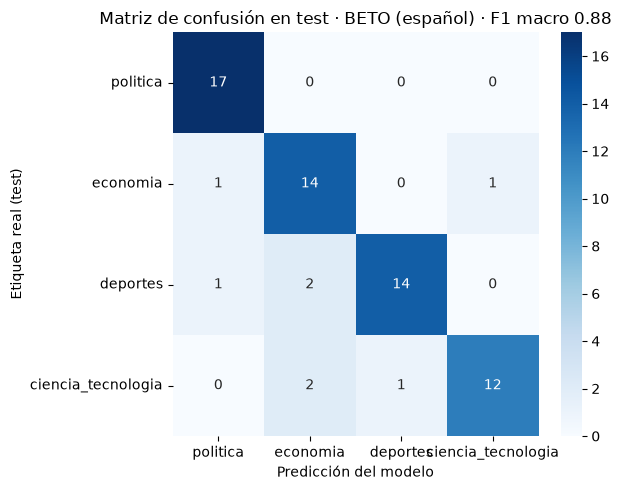

In [27]:
# 7b) Matriz de confusión
cm = confusion_matrix(y_true, y_pred, labels=range(len(CATEGORIAS)))
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción del modelo")
plt.ylabel("Etiqueta real (test)")
plt.title(f"Matriz de confusión en test · {GANADOR} · F1 macro {f1_ft:.2f}")
plt.tight_layout()
plt.savefig("figuras/matriz_confusion_test.png", dpi=120)
plt.show()

**Lectura de la matriz:** 57 de 65 titulares están en la diagonal (aciertos) y hay 8 errores. **Política** no tiene
errores (17/17). **Economía** funciona como categoría "imán": recibe 4 titulares de otras secciones (2 de deportes y 2
de ciencia y tecnología), lo que explica su menor precisión (0.78).Los errores hacia economía no son de gestión deportiva, sino de noticias con vocabulario de marcas, ventas o logística (ASICS Golden Run, ventas de smartphones), y de fenómenos con impacto económico (El Niño).

In [28]:
# 7c) F1 por categoría y errores
f1_cat = {c: reporte[c]["f1-score"] for c in CATEGORIAS}
mejor, peor = max(f1_cat, key=f1_cat.get), min(f1_cat, key=f1_cat.get)
print("F1 por categoría:", {k: round(v, 3) for k, v in f1_cat.items()})
print(f"Mejor: {mejor} ({f1_cat[mejor]:.2f}) | Peor: {peor} ({f1_cat[peor]:.2f})")

test_out = df[df["particion"] == "test"].copy()
test_out["pred"] = [ID2LABEL[i] for i in y_pred]
errores = test_out[test_out["pred"] != test_out["etiqueta"]][["titular", "etiqueta", "pred"]]
print(f"\nErrores en test: {len(errores)}")
pd.set_option("display.max_colwidth", None)
errores

F1 por categoría: {'politica': 0.944, 'economia': 0.824, 'deportes': 0.875, 'ciencia_tecnologia': 0.857}
Mejor: politica (0.94) | Peor: economia (0.82)

Errores en test: 8


,titular,etiqueta,pred
94,IA y Sandbox regulatorio,economia,ciencia_tecnologia
165,"Mourinho sorprende con mensaje sobre Vinícius: “Si estuviese en su lugar, probablemente no estaría aquí”",deportes,politica
198,ASICS Golden Run 2026: así será el desvío vehicular y acceso peatonal el día de la competencia,deportes,economia
304,Mincetur designa a Roxana Barrantes como nuevo miembro del Consejo Directivo de Indecopi,economia,politica
333,La Ruta del Pejerrey 2026 será el 12 de diciembre: carrera solidaria unirá Miraflores y La Punta a beneficio de niños con cáncer,deportes,economia
356,"Ventas de ‘smartphones’ registran una caída del 20%, motivado por la crisis de memoria RAM",ciencia_tecnologia,economia
362,El Niño alcanza niveles récord en el Pacífico antes de llegar a su punto máximo: ¿qué está ocurriendo?,ciencia_tecnologia,economia
412,“Ace Combat 8: Wings of Theve” eleva la franquicia a alturas insospechadas | Reseña,ciencia_tecnologia,deportes


**Reflexión por categoría**
- **Mejor desempeño: política (F1 0.94, 17/17).** Su vocabulario es muy distintivo (Congreso, ministro, senador,
  JNE, partidos) y aparece en casi todos sus titulares.
- **Peor desempeño: economía (F1 0.82, precisión 0.78).** Funciona como categoría "imán": recibe titulares que
  mencionan marcas, ventas o logística aunque sean de otra sección ("ASICS Golden Run…: desvío vehicular", "Ventas de
  smartphones caen 20 %") y fenómenos con impacto económico ("El Niño alcanza niveles récord"). Además, pierde
  titulares cortos o "creativos" de columnas ("IA y Sandbox regulatorio"), el mismo tipo detectado en la validación
  de la Parte 1.
- **Deportes (F1 0.88):** falla cuando el titular no trata de una competencia: eventos solidarios y logística
  (Ruta del Pejerrey, ASICS) o **citas textuales** ("Mourinho: 'Si estuviese en su lugar…'"), que imitan el estilo
  de las declaraciones políticas.
- **Ciencia y tecnología (F1 0.86):** la categoría más heterogénea (ciencia, clima, gadgets, videojuegos). Una reseña
  de videojuego ("Ace Combat 8") terminó en deportes.
- **¿Error del modelo o etiqueta discutible?** Al menos 3 de los 8 errores son discutibles: el nombramiento en
  Indecopi (¿economía o política?), la caída de ventas de smartphones (¿tecnología o economía?) y El Niño. La
  etiqueta por sección del diario no siempre coincide con el tema principal, así que el F1 real del modelo
  probablemente es algo mayor que 0.875.

### Paso 8 · Comparativa y decisión
**Objetivo:** comparar los tres enfoques en **precisión, costo y velocidad**.

**Qué hace:** evalúa también las etiquetas del LLM sobre el mismo test (contra la etiqueta del diario), para comparar
en igualdad de condiciones, y arma una tabla con F1, latencia, costo y si necesita internet.

**Resultado esperado:** la tabla comparativa de los tres enfoques.

In [32]:
t_llm = df[df["particion"] == "test"].dropna(subset=["etiqueta_llm"])
acc_llm = accuracy_score(t_llm["etiqueta"], t_llm["etiqueta_llm"])
f1_llm = f1_score(t_llm["etiqueta"], t_llm["etiqueta_llm"], average="macro")

comparativa = pd.DataFrame([
    {"Enfoque": "Zero-shot (BERT español XNLI)", "Evaluado en": f"{len(muestra_zs)} titulares de test",
     "Accuracy": acc_zs, "F1 macro": f1_zs, "Latencia (s/titular)": lat_zs,
     "Costo": "Gratis, local", "Requiere internet": "No"},
    {"Enfoque": f"LLM ({MODELO_LLM})", "Evaluado en": f"{len(t_llm)} titulares de test",
     "Accuracy": acc_llm, "F1 macro": f1_llm, "Latencia (s/titular)": LAT_LLM,
     "Costo": f"Cuota gratuita limitada (errores 503/429); de pago al escalar (≈{TOKENS_ENTRADA:,} tokens de entrada para {len(df)} titulares)",     "Requiere internet": "Sí"},
    {"Enfoque": f"{GANADOR} fine-tuned", "Evaluado en": f"{len(y_true)} titulares de test",
     "Accuracy": acc_ft, "F1 macro": f1_ft, "Latencia (s/titular)": lat_ft,
     "Costo": "Entrenamiento único; uso local gratuito", "Requiere internet": "No"},
]).round(3)
comparativa

,Enfoque,Evaluado en,Accuracy,F1 macro,Latencia (s/titular),Costo,Requiere internet
0,Zero-shot (BERT español XNLI),40 titulares de test,0.575,0.542,0.490,"Gratis, local",No
1,LLM (gemini-flash-latest),65 titulares de test,0.908,0.902,3.614,"Cuota gratuita limitada (errores 503/429); de pago al escalar (≈16,722 tokens de entrada para 433 titulares)",Sí
2,BETO (español) fine-tuned,65 titulares de test,0.877,0.875,0.061,Entrenamiento único; uso local gratuito,No


**Decisión para un entorno real:** elegiría **BETO fine-tuned** para el dashboard y la clasificación diaria, y
dejaría el **LLM como etiquetador**.

1. **Precisión:** el LLM obtiene el F1 más alto en test (0.90), pero BETO queda muy cerca (0.875; conserva ~97 % del
   desempeño) y ambos superan con amplitud al zero-shot (0.54).
2. **Costo:** el LLM depende de una API externa. Con la cuota gratuita hubo errores de alta demanda (503) y de cuota
   agotada (429), y etiquetar 433 titulares requirió dos sesiones. A mayor escala sería de pago. BETO se entrena una
   vez (≈3 min en CPU) y luego clasifica gratis en la propia computadora.
3. **Velocidad y disponibilidad:** BETO clasifica en ~0.06 s por titular y sin internet; el LLM tardó ~3.6 s por
   titular (incluye pausas y reintentos por la cuota) y depende de que el servicio esté disponible.

**Esquema recomendado:** usar el LLM solo para etiquetar datos nuevos de vez en cuando (con auditoría humana de una
muestra, como la de 19/20) y reentrenar BETO con ellos. BETO es el modelo que se despliega en el dashboard.

### Paso 9 · Guardar métricas y resumen para la entrega
**Objetivo:** dejar los resultados en archivos livianos que usará el dashboard (Parte 3).

**Qué hace:** guarda `modelo/metricas.json` y `modelo/comparativa.csv`, e imprime la línea que va en el comentario
de entrega del Issue.

**Resultado esperado:** la línea `Resultados Test: F1 Macro: … | Zero-shot: … | Acuerdo LLM-Humano: …`.

In [34]:
resumen_metricas = {
    "f1_macro_test": round(float(f1_ft), 4),
    "accuracy_test": round(float(acc_ft), 4),
    "f1_macro_zero_shot": round(float(f1_zs), 4),
    "f1_macro_llm_test": round(float(f1_llm), 4),
    "acuerdo_llm_humano": ACUERDO_LLM_HUMANO,
    "n_noticias": int(len(df)), "n_test": int(len(y_true)),
    "modelo_base": MODELO_BASE, "modelo_llm": MODELO_LLM,
    "f1_por_categoria": {k: round(v, 4) for k, v in f1_cat.items()},
    "modelos_probados": tabla_modelos[["Modelo", "F1 macro (validación)"]].to_dict("records"),
}
with open("modelo/metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumen_metricas, f, ensure_ascii=False, indent=2)
comparativa.to_csv("modelo/comparativa.csv", index=False, encoding="utf-8-sig")

print(f"Resultados Test: F1 Macro: {f1_ft:.2f} | Zero-shot: {f1_zs:.2f} | Acuerdo LLM-Humano: {ACUERDO_LLM_HUMANO}")

Resultados Test: F1 Macro: 0.88 | Zero-shot: 0.54 | Acuerdo LLM-Humano: 19/20


## Conclusiones de la Parte 2
- **Sí se puede convertir titulares peruanos en un clasificador:** el modelo BETO fine-tuned alcanzó un **F1 macro
  de 0.88** en el test reservado (65 titulares), frente a **0.54** del zero-shot sin entrenamiento (+0.33).
- **Supervisión débil confiable:** Gemini etiquetó los 433 titulares, coincidió con la sección del diario en el
  93.5 % de los casos y con la revisión humana en **19/20** (95 %). El único desacuerdo fue un titular que mezcla
  política y economía (UE–Minem).
- **El idioma del modelo importa:** BETO (español) obtuvo F1 0.954 en validación frente a 0.733 de ModernBERT (inglés).
  BETO parte los titulares en palabras completas y ModernBERT los fragmenta, con las tildes partidas en bytes.
- **Categorías:** política es la más fácil (F1 0.94) y economía la más difícil (F1 0.82), porque atrae titulares con
  vocabulario de marcas, ventas o impacto económico. Varios "errores" son en realidad etiquetas discutibles de la
  sección del diario.
- **Decisión:** BETO se despliega en el dashboard (0.06 s por titular, gratis y sin internet), con un desempeño cercano
  al del LLM (0.875 vs 0.902). El LLM queda como herramienta para etiquetar datos nuevos con auditoría humana.